# **Imports**

In [3]:
import pandas as pd
import numpy as np
import re
import string
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import spacy

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer

In [2]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


True

# **Load Data**

In [5]:
json_url = "https://drive.google.com/uc?export=download&id=1vZ8q7iNISzV2tYkeV2Rh3w6yb-zFB0xk"
df = pd.read_json(json_url)

csv_url = "https://drive.google.com/uc?export=download&id=12_r2wb8e0XZCYUUpsL-zaAjtrn6obGZm"
validation = pd.read_csv(csv_url)


# **Data Validation**

In [6]:
print("Dataset principal:", df.shape)
print("Validation labels:", validation.shape)

Dataset principal: (28080, 17)
Validation labels: (40, 4)


In [7]:
df.head(20)

,_id,actual_price,average_rating,brand,category,crawled_at,description,discount,images,out_of_stock,pid,product_details,seller,selling_price,sub_category,title,url
0,fa8e22d6-c0b6-5229-bb9e-ad52eda39a0a,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:51,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EA7H5FYZH,"[{'Style Code': '1005COMBO2'}, {'Closure': 'El...",Shyam Enterprises,921,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
1,893e6980-f2a0-531f-b056-34dd63fe912c,"1,499",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,66% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EJZV2UVRZ,"[{'Style Code': '1005BLUE'}, {'Closure': 'Draw...",Shyam Enterprises,499,Bottomwear,Solid Men Blue Track Pants,https://www.flipkart.com/yorker-solid-men-blue...
2,eb4c8eab-8206-59d0-bcd1-a724d96bf74f,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:52,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EHFCY5Z4Y,"[{'Style Code': '1005COMBO4'}, {'Closure': 'El...",Shyam Enterprises,931,Bottomwear,Solid Men Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
3,3f3f97bb-5faf-57df-a9ff-1af24e2b1045,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:53,Yorker trackpants made from 100% rich combed c...,69% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9ESZZ7YWEF,"[{'Style Code': '1005COMBO3'}, {'Closure': 'El...",Shyam Enterprises,911,Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
4,750caa3d-6264-53ca-8ce1-94118a1d8951,"2,999",3.9,York,Clothing and Accessories,2021-02-10 20:11:53,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EVXKBSUD7,"[{'Style Code': '1005COMBO1'}, {'Closure': 'Dr...",Shyam Enterprises,943,Bottomwear,"Solid Women Brown, Grey Track Pants",https://www.flipkart.com/yorker-solid-men-brow...
5,9af4ac75-230b-5d51-8bbf-2ffb19aaa763,"4,499",3.8,York,Clothing and Accessories,2021-02-10 20:11:54,Yorker trackpants made from 100% rich combed c...,74% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9EFK9DNWDA,"[{'Style Code': '1005COMBO12'}, {'Closure': 'E...",Shyam Enterprises,"1,169",Bottomwear,Solid Women Multicolor Track Pants,https://www.flipkart.com/yorker-solid-men-mult...
6,1b1d40cc-4eaa-54cf-8938-e59ecae5f19e,"1,499",3.8,York,Clothing and Accessories,2021-02-10 20:11:54,Yorker trackpants made from 100% rich combed c...,68% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFDABN3GXYPFHE,"[{'Style Code': '1005NAVI'}, {'Closure': 'Elas...",Shyam Enterprises,466,Bottomwear,Solid Women Dark Blue Track Pants,https://www.flipkart.com/yorker-solid-men-dark...
7,a33cf2e2-c5e4-5f06-b3aa-8f46a6fd1aef,"1,499",3.8,York,Clothing and Accessories,2021-02-10 20:11:55,Yorker trackpants made from 100% rich combed c...,63% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9ESGZYT8NH,"[{'Style Code': '1005DSKIN'}, {'Closure': 'Ela...",Shyam Enterprises,545,Bottomwear,Solid Women Beige Track Pants,https://www.flipkart.com/yorker-solid-men-beig...
8,ab4f0cca-6a84-51e1-b7e8-523724db8728,"1,499",3.8,York,Clothing and Accessories,2021-02-10 20:11:55,Yorker trackpants made from 100% rich combed c...,67% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFCZ9DYU33FFXS,"[{'Style Code': '1005BLACK'}, {'Closure': 'Dra...",Shyam Enterprises,489,Bottomwear,Solid Women Black Track Pants,https://www.flipkart.com/yorker-solid-men-blac...
9,f8a91e89-c5db-5fa5-9428-1f580a72d05e,"1,499",3.7,York,Clothing and Accessories,2021-02-10 20:11:56,Yorker trackpants made from 100% rich combed c...,64% off,[https://rukminim1.flixcart.com/image/128/128/...,False,TKPFDABN4NQFVKZY,

In [8]:
validation.head()

,title,pid,query_id,labels
0,Full Sleeve Printed Women Sweatshirt,SWSFFVKBCQG5FHPF,1,1
1,Full Sleeve Striped Women Sweatshirt,SWSFJY5ZFHQ7HXKW,1,0
2,Full Sleeve Printed Women Sweatshirt,SWSFUY89NHMZHZPX,1,1
3,Full Sleeve Graphic Print Women Sweatshirt,SWSFXQ5YX6RZKHP4,1,1
4,Full Sleeve Solid Women Sweatshirt,JCKFTZBC3DMCVYXH,1,0


In [10]:
print("DATA VALIDATION SUMMARY")

# Shape
print("\nDataset shape:")
print(df.shape)

# Missing values (NaN / None)
print("\nMissing values per column:")
print(df.isnull().sum().sort_values(ascending=False))

# Empty strings in important text fields
text_columns = ["title", "description", "brand", "category", "sub_category", "seller"]

print("\nEmpty strings in important text fields:")
for col in text_columns:
    empty_count = (
        df[col]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )
    print(f"{col}: {empty_count}")

# Duplicate product IDs
print("\nDuplicate PID values:")
print(df["pid"].duplicated().sum())

# Unique product IDs
print("\nUnique PID values:")
print(df["pid"].nunique())

# Check out_of_stock values
print("\nout_of_stock values:")
print(df["out_of_stock"].value_counts(dropna=False))

# Numeric fields summary
print("\nNumeric fields summary:")
display(
    df[["selling_price", "actual_price", "average_rating"]].describe()
)

DATA VALIDATION SUMMARY

Dataset shape:
(28080, 17)

Missing values per column:
_id                0
actual_price       0
average_rating     0
brand              0
category           0
crawled_at         0
description        0
discount           0
images             0
out_of_stock       0
pid                0
product_details    0
seller             0
selling_price      0
sub_category       0
title              0
url                0
dtype: int64

Empty strings in important text fields:
title: 0
description: 11150
brand: 2009
category: 0
sub_category: 0
seller: 1643

Duplicate PID values:
0

Unique PID values:
28080

out_of_stock values:
out_of_stock
False    26436
True      1644
Name: count, dtype: int64

Numeric fields summary:


,selling_price,actual_price,average_rating
count,28080,28080,28080
unique,1512,728,39
top,399,999,3.9
freq,1500,3504,2605


### Conclusions

- The dataset contains **28,080 products and 17 attributes**
- No missing values (NaN or None) were detected in any column
- However, some text fields contain empty strings. In particular, **11,150 descriptions**, **2,009 brands**, and **1,643 sellers** are empty. Titles, categories and subcategories do not contain empty strings
- No duplicated `pid` values were found, and there are **28,080 unique product IDs**, meaning that each product is uniquely identified
- Most products are available: **26,436 products are in stock**, while **1,644 are out of stock**
- The fields selling_price, actual_price, and average_rating are currently interpreted as non-numerical values, so they should be converted to appropriate numeric types before further analysis or processing
- Overall, the dataset is structurally consistent, but empty textual fields and numeric type conversion must be handled during preprocessing

# **Pre-processing**

## Text Preprocessing

The main textual fields, `title` and `description`, are preprocessed by converting text to lowercase, tokenizing it, removing punctuation and stop words, and applying stemming.

The original fields are kept unchanged so that they can still be shown in the final search results.

In [11]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

nltk.download("stopwords")

stop_words = set(stopwords.words("english"))
stemmer = PorterStemmer()


def preprocess_text(text):
    if text is None:
        return []

    text = str(text).lower()

    # Tokenization + punctuation removal
    tokens = re.findall(r'\b[a-z0-9]+\b', text)

    # Remove stopwords
    tokens = [word for word in tokens if word not in stop_words]

    # Stemming
    tokens = [stemmer.stem(word) for word in tokens]

    return tokens


# Keep original dataframe untouched
df_processed = df.copy()

# Main textual fields
df_processed["title_processed"] = df_processed["title"].apply(preprocess_text)
df_processed["description_processed"] = df_processed["description"].apply(preprocess_text)

df_processed[
    ["title", "title_processed", "description", "description_processed"]
].head()

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


,title,title_processed,description,description_processed
0,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
1,Solid Men Blue Track Pants,"[solid, men, blue, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
2,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
3,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."
4,"Solid Women Brown, Grey Track Pants","[solid, women, brown, grey, track, pant]",Yorker trackpants made from 100% rich combed c...,"[yorker, trackpant, made, 100, rich, comb, cot..."


## Additional Text Fields

The fields `brand`, `category`, `sub_category`, `product_details`, and `seller` are also preprocessed.

We keep these fields separately because they may have different importance during ranking. `product_details` is first converted from its structured format into text before applying the same preprocessing steps.

In [12]:
def product_details_to_text(value):
    if isinstance(value, list):
        parts = []

        for item in value:
            if isinstance(item, dict):
                for key, val in item.items():
                    parts.append(str(key))
                    parts.append(str(val))
            else:
                parts.append(str(item))

        return " ".join(parts)

    elif isinstance(value, dict):
        parts = []

        for key, val in value.items():
            parts.append(str(key))
            parts.append(str(val))

        return " ".join(parts)

    return str(value)


df_processed["brand_processed"] = (
    df_processed["brand"]
    .fillna("")
    .apply(preprocess_text)
)

df_processed["category_processed"] = (
    df_processed["category"]
    .fillna("")
    .apply(preprocess_text)
)

df_processed["sub_category_processed"] = (
    df_processed["sub_category"]
    .fillna("")
    .apply(preprocess_text)
)

df_processed["seller_processed"] = (
    df_processed["seller"]
    .fillna("")
    .apply(preprocess_text)
)

df_processed["product_details_processed"] = (
    df_processed["product_details"]
    .apply(product_details_to_text)
    .apply(preprocess_text)
)

df_processed[
    [
        "brand_processed",
        "category_processed",
        "sub_category_processed",
        "product_details_processed",
        "seller_processed"
    ]
].head()

,brand_processed,category_processed,sub_category_processed,product_details_processed,seller_processed
0,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo2, closur, elast, pocke...","[shyam, enterpris]"
1,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005blue, closur, drawstr, elast...","[shyam, enterpris]"
2,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo4, closur, elast, pocke...","[shyam, enterpris]"
3,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo3, closur, elast, pocke...","[shyam, enterpris]"
4,[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo1, closur, drawstr, ela...","[shyam, enterpris]"


## Field Indexing Strategy

We use a hybrid strategy. The processed fields are kept separately so that they can later receive different weights during ranking, but the main textual fields are also combined into `search_tokens` to simplify retrieval.

Keeping the fields separately gives more flexibility and preserves information about where each term appeared, but it makes the ranking process more complex. Combining them makes retrieval simpler, but loses field-specific information.

The `seller` field is kept separately because it is usually less descriptive of the product itself.

In [13]:
df_processed["search_tokens"] = (
    df_processed["title_processed"]
    + df_processed["description_processed"]
    + df_processed["brand_processed"]
    + df_processed["category_processed"]
    + df_processed["sub_category_processed"]
    + df_processed["product_details_processed"]
)

In [14]:
df_processed[
    [
        "title",
        "title_processed",
        "description_processed",
        "brand_processed",
        "category_processed",
        "sub_category_processed",
        "product_details_processed",
        "search_tokens"
    ]
].head()

,title,title_processed,description_processed,brand_processed,category_processed,sub_category_processed,product_details_processed,search_tokens
0,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo2, closur, elast, pocke...","[solid, women, multicolor, track, pant, yorker..."
1,Solid Men Blue Track Pants,"[solid, men, blue, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005blue, closur, drawstr, elast...","[solid, men, blue, track, pant, yorker, trackp..."
2,Solid Men Multicolor Track Pants,"[solid, men, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo4, closur, elast, pocke...","[solid, men, multicolor, track, pant, yorker, ..."
3,Solid Women Multicolor Track Pants,"[solid, women, multicolor, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo3, closur, elast, pocke...","[solid, women, multicolor, track, pant, yorker..."
4,"Solid Women Brown, Grey Track Pants","[solid, women, brown, grey, track, pant]","[yorker, trackpant, made, 100, rich, comb, cot...",[york],"[cloth, accessori]",[bottomwear],"[style, code, 1005combo1, closur, drawstr, ela...","[solid, women, brown, grey, track, pant, yorke..."


## Numerical and Boolean Fields

The fields `selling_price`, `actual_price`, `discount`, and `average_rating` are not indexed as textual terms. Instead, they are converted to numerical values so they can later be used for filtering or ranking.

The `out_of_stock` field is kept as a boolean value and is also excluded from the textual index.

In [15]:
def clean_numeric(value):
    if pd.isna(value):
        return np.nan

    value = str(value).replace(",", "")
    value = re.sub(r"[^\d.]", "", value)

    if value == "":
        return np.nan

    return float(value)


def clean_discount(value):
    if pd.isna(value):
        return np.nan

    match = re.search(r"\d+", str(value))

    if match:
        return float(match.group())

    return np.nan


df_processed["selling_price_numeric"] = (
    df_processed["selling_price"].apply(clean_numeric)
)

df_processed["actual_price_numeric"] = (
    df_processed["actual_price"].apply(clean_numeric)
)

df_processed["average_rating_numeric"] = (
    df_processed["average_rating"].apply(clean_numeric)
)

df_processed["discount_numeric"] = (
    df_processed["discount"].apply(clean_discount)
)

In [16]:
df_processed[
    [
        "selling_price",
        "selling_price_numeric",
        "actual_price",
        "actual_price_numeric",
        "discount",
        "discount_numeric",
        "average_rating",
        "average_rating_numeric",
        "out_of_stock"
    ]
].head(10)

,selling_price,selling_price_numeric,actual_price,actual_price_numeric,discount,discount_numeric,average_rating,average_rating_numeric,out_of_stock
0,921,921.0,"2,999",2999.0,69% off,69.0,3.9,3.9,False
1,499,499.0,"1,499",1499.0,66% off,66.0,3.9,3.9,False
2,931,931.0,"2,999",2999.0,68% off,68.0,3.9,3.9,False
3,911,911.0,"2,999",2999.0,69% off,69.0,3.9,3.9,False
4,943,943.0,"2,999",2999.0,68% off,68.0,3.9,3.9,False
5,"1,169",1169.0,"4,499",4499.0,74% off,74.0,3.8,3.8,False
6,466,466.0,"1,499",1499.0,68% off,68.0,3.8,3.8,False
7,545,545.0,"1,499",1499.0,63% off,63.0,3.8,3.8,False
8,489,489.0,"1,499",1499.0,67% off,67.0,3.8,3.8,False
9,531,531.0,"1,499",1499.0,64% off,64.0,3.7,3.7,False


In [17]:
print(validation.columns.tolist())
display(validation.head(10))

['title', 'pid', 'query_id', 'labels']


,title,pid,query_id,labels
0,Full Sleeve Printed Women Sweatshirt,SWSFFVKBCQG5FHPF,1,1
1,Full Sleeve Striped Women Sweatshirt,SWSFJY5ZFHQ7HXKW,1,0
2,Full Sleeve Printed Women Sweatshirt,SWSFUY89NHMZHZPX,1,1
3,Full Sleeve Graphic Print Women Sweatshirt,SWSFXQ5YX6RZKHP4,1,1
4,Full Sleeve Solid Women Sweatshirt,JCKFTZBC3DMCVYXH,1,0
5,Full Sleeve Graphic Print Women Sweatshirt,SWSFWCTDHRABJFCR,1,1
6,Typography Women V Neck Multicolor T-Shirt (P...,TSHFUH9FABXHSDPJ,1,0
7,Full Sleeve Printed Women Sweatshirt,SWSFVGKENHBSVUWJ,1,1
8,Full Sleeve Solid Women Sweatshirt,JCKF7M8DNBB6WZ8Y,1,1
9,Full Sleeve Graphic Print Women Sweatshirt,SWSFWCSPEGMDH8FV,1,1


In [18]:
query_map = {
    1: "women full sleeve sweatshirt cotton",
    2: "men slim jeans blue"
}

validation_analysis = validation.merge(
    df_processed,
    on="pid",
    how="left",
    suffixes=("_validation", "")
)

validation_analysis["query"] = validation_analysis["query_id"].map(query_map)

display(
    validation_analysis[
        [
            "query_id",
            "query",
            "labels",
            "pid",
            "title",
            "title_processed",
            "description_processed",
            "brand_processed",
            "category_processed",
            "sub_category_processed",
            "product_details_processed"
        ]
    ].head(10)
)

,query_id,query,labels,pid,title,title_processed,description_processed,brand_processed,category_processed,sub_category_processed,product_details_processed
0,1,women full sleeve sweatshirt cotton,1,SWSFFVKBCQG5FHPF,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[hoodi, women, stylish, made, 100, premium, co...",[cupidsto],"[cloth, accessori]","[winter, wear]","[color, dark, blue, fabric, cotton, blend, pat..."
1,1,women full sleeve sweatshirt cotton,0,SWSFJY5ZFHQ7HXKW,Full Sleeve Striped Women Sweatshirt,"[full, sleev, stripe, women, sweatshirt]","[squat, press, shuttl, run, women, train, hood...",[reeb],"[cloth, accessori]","[winter, wear]","[color, black, fabric, polyest, blend, pattern..."
2,1,women full sleeve sweatshirt cotton,1,SWSFUY89NHMZHZPX,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[product, stori, live, larg, big, logo, women,...",[pu],"[cloth, accessori]","[winter, wear]","[color, red, fabric, cotton, blend, pattern, p..."
3,1,women full sleeve sweatshirt cotton,1,SWSFXQ5YX6RZKHP4,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, print, sweatshirt, fea...","[free, authori]","[cloth, accessori]","[winter, wear]","[color, yellow, fabric, polycotton, pattern, g..."
4,1,women full sleeve sweatshirt cotton,0,JCKFTZBC3DMCVYXH,Full Sleeve Solid Women Sweatshirt,"[full, sleev, solid, women, sweatshirt]","[product, stori, embrac, next, gener, sport, u...",[pu],"[cloth, accessori]","[winter, wear]","[color, green, fabric, cotton, blend, pattern,..."
5,1,women full sleeve sweatshirt cotton,1,SWSFWCTDHRABJFCR,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, crew, neck, terri, swe...","[free, authori]","[cloth, accessori]","[winter, wear]","[color, red, fabric, polycotton, pattern, grap..."
6,1,women full sleeve sweatshirt cotton,0,TSHFUH9FABXHSDPJ,Typography Women V Neck Multicolor T-Shirt (P...,"[typographi, women, v, neck, multicolor, shirt...","[free, author, present, v, neck, tee, combo, f...","[free, authori]","[cloth, accessori]",[topwear],"[type, v, neck, sleev, half, sleev, fit, regul..."
7,1,women full sleeve sweatshirt cotton,1,SWSFVGKENHBSVUWJ,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[product, stori, celebr, global, connect, fash...",[pu],"[cloth, accessori]","[winter, wear]","[color, white, fabric, cotton, blend, pattern,..."
8,1,women full sleeve sweatshirt cotton,1,JCKF7M8DNBB6WZ8Y,Full Sleeve Solid Women Sweatshirt,"[full, sleev, solid, women, sweatshirt]","[reebok, bomber, track, jacket, women, comfort...",[reeb],"[cloth, accessori]","[winter, wear]","[color, black, fabric, cotton, blend, pattern,..."
9,1,women full sleeve sweatshirt cotton,1,SWSFWCSPEGMDH8FV,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, crew, neck, sweatshirt...","[free, authori]","[cloth, accessori]","[winter, wear]","[color, red, fabric, polycotton, pattern, grap..."


In [19]:
validation_analysis.groupby(
    ["query_id", "labels"]
).size()

query_id  labels
1         0          7
          1         13
2         0         10
          1         10
dtype: int64

In [20]:
display(
    validation_analysis[
        validation_analysis["labels"] == 1
    ][
        [
            "query_id",
            "query",
            "title",
            "title_processed",
            "description_processed",
            "brand_processed",
            "sub_category_processed",
            "product_details_processed"
        ]
    ]
)

,query_id,query,title,title_processed,description_processed,brand_processed,sub_category_processed,product_details_processed
0,1,women full sleeve sweatshirt cotton,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[hoodi, women, stylish, made, 100, premium, co...",[cupidsto],"[winter, wear]","[color, dark, blue, fabric, cotton, blend, pat..."
2,1,women full sleeve sweatshirt cotton,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[product, stori, live, larg, big, logo, women,...",[pu],"[winter, wear]","[color, red, fabric, cotton, blend, pattern, p..."
3,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, print, sweatshirt, fea...","[free, authori]","[winter, wear]","[color, yellow, fabric, polycotton, pattern, g..."
5,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, crew, neck, terri, swe...","[free, authori]","[winter, wear]","[color, red, fabric, polycotton, pattern, grap..."
7,1,women full sleeve sweatshirt cotton,Full Sleeve Printed Women Sweatshirt,"[full, sleev, print, women, sweatshirt]","[product, stori, celebr, global, connect, fash...",[pu],"[winter, wear]","[color, white, fabric, cotton, blend, pattern,..."
8,1,women full sleeve sweatshirt cotton,Full Sleeve Solid Women Sweatshirt,"[full, sleev, solid, women, sweatshirt]","[reebok, bomber, track, jacket, women, comfort...",[reeb],"[winter, wear]","[color, black, fabric, cotton, blend, pattern,..."
9,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[free, author, present, crew, neck, sweatshirt...","[free, authori]","[winter, wear]","[color, red, fabric, polycotton, pattern, grap..."
10,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[wear, nasa, logo, edit, women, cotton, sweats...","[tee, bud]","[winter, wear]","[color, grey, fabric, pure, cotton, pattern, g..."
14,1,women full sleeve sweatshirt cotton,Full Sleeve Color Block Women Sweatshirt,"[full, sleev, color, block, women, sweatshirt]","[freshen, winter, wardrob, sweatshirt, women, ...","[jack, har]","[winter, wear]","[color, multicolor, fabric, fleec, pattern, co..."
15,1,women full sleeve sweatshirt cotton,Full Sleeve Graphic Print Women Sweatshirt,"[full, sleev, graphic, print, women, sweatshirt]","[temperatur, dip, lower, time, invest, sweatsh...","[free, authori]","[winter, wear]","[color, maroon, fabric, pure, cotton, pattern,..."


In [21]:
field_columns = [
    "title_processed",
    "description_processed",
    "brand_processed",
    "category_processed",
    "sub_category_processed",
    "product_details_processed"
]

# Process each validation query using the same preprocessing
query_tokens = {
    query_id: preprocess_text(query)
    for query_id, query in query_map.items()
}

def query_term_coverage(row, field):
    q_tokens = query_tokens[row["query_id"]]
    field_tokens = row[field]

    if len(q_tokens) == 0:
        return 0

    matches = sum(token in field_tokens for token in q_tokens)

    return matches / len(q_tokens)


for field in field_columns:
    validation_analysis[field + "_coverage"] = validation_analysis.apply(
        lambda row: query_term_coverage(row, field),
        axis=1
    )

coverage_columns = [field + "_coverage" for field in field_columns]

coverage_summary = (
    validation_analysis
    .groupby(["query_id", "labels"])[coverage_columns]
    .mean()
)

display(coverage_summary.round(3))

title_processed_coverage  description_processed_coverage  \
query_id labels                                                             
1        0                          0.457                           0.629   
         1                          0.800                           0.585   
2        0                          0.725                           0.400   
         1                          0.800                           0.350   

                 brand_processed_coverage  category_processed_coverage  \
query_id labels                                                          
1        0                            0.0                          0.0   
         1                            0.0                          0.0   
2        0                            0.0                          0.0   
         1                            0.0                          0.0   

                 sub_category_processed_coverage  \
query_id labels                                    
1        0                                   0.0   
         1                                   0.0   
2        0                                   0.0   
         1                                   0.0   

                 product_details_processed_coverage  
query_id labels                                      
1        0                                    0.600  
         1                                    0.800  
2        0                                    0.475  
         1                                    0.650

### Validation Labels Analysis

We used the validation set to check which fields are more useful for matching the two given queries.

The results show that the `title` is the most useful field, since relevant documents usually contain more query terms in the title than non-relevant ones.

`product_details` is also useful because some important information, such as material or product characteristics, may not appear in the title but can be found in this field.

On the other hand, `description` does not clearly separate relevant and non-relevant documents. In fact, for these two queries, some non-relevant documents have a similar or even higher term coverage in the description. Because of this, we think that matches in the description should probably have less importance than matches in the title.

The fields `brand`, `category`, and `sub_category` do not match the terms of these two queries directly. However, we decided to keep them as separate fields because they can still be useful for other types of queries or for future filtering and ranking.

For this reason, we keep the fields separately, but we also combine the main textual fields into `search_tokens`. This makes the retrieval process easier while still allowing us to give different importance to each field later

## Exploratory Data Analysis
In this section, we examine both the text features (titles, descriptions, vocabulary) and the business metrics (prices, discounts, ratings, top brands, and stock status) to get a full picture of our product dataset.

# 1. Body & Vocabulary Statistics
Here we analyze the text complexity of the dataset by computing vocabulary size, document word count distributions, and average sentence lengths across product titles and descriptions.

VOCABULARY STATISTICS
Total tokens in titles: 176,056
Unique vocabulary size in titles: 728
Total tokens in descriptions: 528,498
Unique vocabulary size in descriptions: 4,697
Total unique vocabulary size across all search fields: 19,613

DOCUMENT LENGTH METRICS


,title_word_count,desc_word_count,desc_avg_sentence_length
count,28080.00,28080.00,28080.00
mean,6.27,18.82,11.25
std,1.98,26.69,14.78
min,1.00,0.00,0.00
25%,5.00,0.00,0.00
50%,6.00,9.00,9.33
75%,7.00,29.00,18.00
max,31.00,579.00,191.00


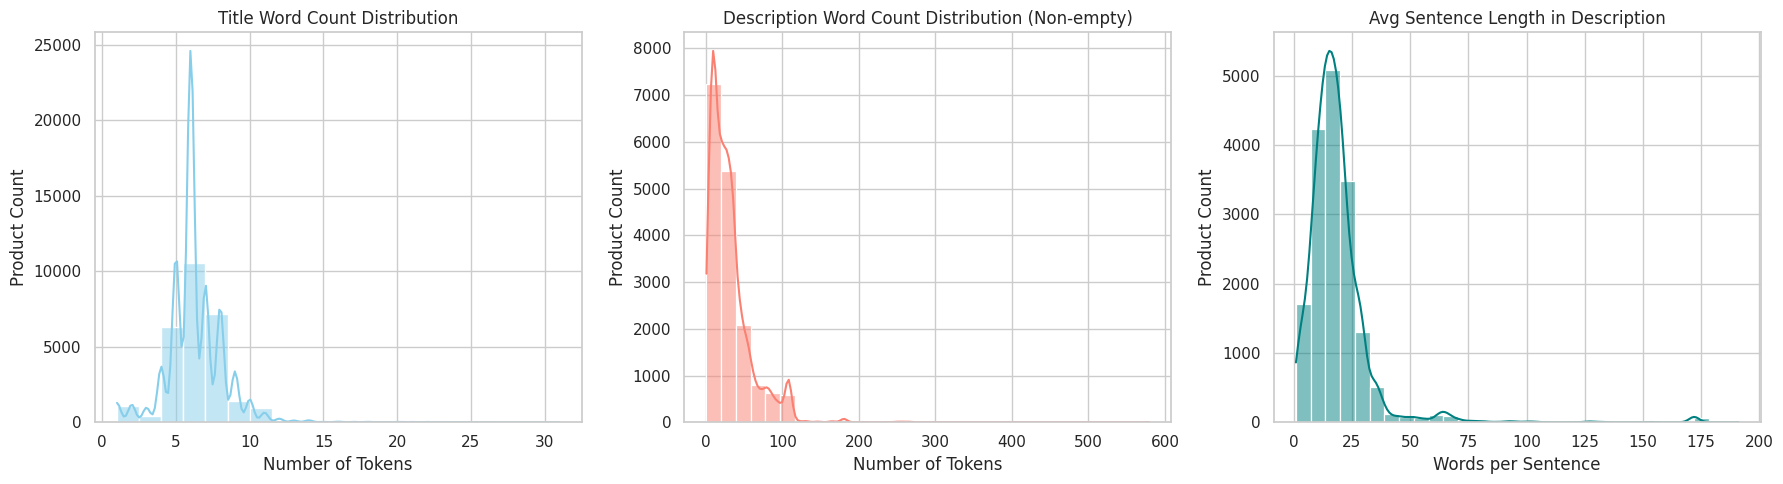

In [33]:
# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

#1. Vocabulary Size
all_title_tokens = [token for tokens in df_processed["title_processed"] for token in tokens]
all_desc_tokens = [token for tokens in df_processed["description_processed"] for token in tokens]
all_corpus_tokens = [token for tokens in df_processed["search_tokens"] for token in tokens]

vocab_title = set(all_title_tokens)
vocab_desc = set(all_desc_tokens)
vocab_total = set(all_corpus_tokens)

print("VOCABULARY STATISTICS")
print(f"Total tokens in titles: {len(all_title_tokens):,}")
print(f"Unique vocabulary size in titles: {len(vocab_title):,}")
print(f"Total tokens in descriptions: {len(all_desc_tokens):,}")
print(f"Unique vocabulary size in descriptions: {len(vocab_desc):,}")
print(f"Total unique vocabulary size across all search fields: {len(vocab_total):,}")

#2. Word Count Distributions
df_processed["title_word_count"] = df_processed["title_processed"].apply(len)
df_processed["desc_word_count"] = df_processed["description_processed"].apply(len)

#3. Average Sentence Length
def get_avg_sentence_length(text):
    if not text or pd.isna(text) or str(text).strip() == "":
        return 0
    sentences = nltk.sent_tokenize(str(text))
    if len(sentences) == 0:
        return 0
    words = nltk.word_tokenize(str(text))
    return len(words) / len(sentences)

df_processed["desc_avg_sentence_length"] = df_processed["description"].apply(get_avg_sentence_length)

# Display Summary Metrics
print("\nDOCUMENT LENGTH METRICS")
display(df_processed[["title_word_count", "desc_word_count", "desc_avg_sentence_length"]].describe().round(2))

# Visualizations
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df_processed["title_word_count"], bins=20, kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Title Word Count Distribution")
axes[0].set_xlabel("Number of Tokens")
axes[0].set_ylabel("Product Count")

sns.histplot(df_processed[df_processed["desc_word_count"] > 0]["desc_word_count"], bins=30, kde=True, ax=axes[1], color="salmon")
axes[1].set_title("Description Word Count Distribution (Non-empty)")
axes[1].set_xlabel("Number of Tokens")
axes[1].set_ylabel("Product Count")

sns.histplot(df_processed[df_processed["desc_avg_sentence_length"] > 0]["desc_avg_sentence_length"], bins=30, kde=True, ax=axes[2], color="teal")
axes[2].set_title("Avg Sentence Length in Description")
axes[2].set_xlabel("Words per Sentence")
axes[2].set_ylabel("Product Count")

plt.tight_layout()
plt.show()

This dataset includes 28,080 fashion products with 17 different details, such as titles, descriptions, prices, and stock status. While all items have complete basic information, about 40% of the product descriptions are empty. Product titles are short and consistent, averaging around 6 words each, making them the most reliable place to search for matches. Other details like prices, ratings, and discounts were converted into regular numbers so they can be used to filter or sort products rather than searched as plain text. Finally, almost 94% of the products are currently in stock, providing a solid foundation for building an efficient search system.

# 2. E-Commerce Attributes & Stock Analysis

We analyze seller distribution, top brands, product categories, and inventory status (out_of_stock).

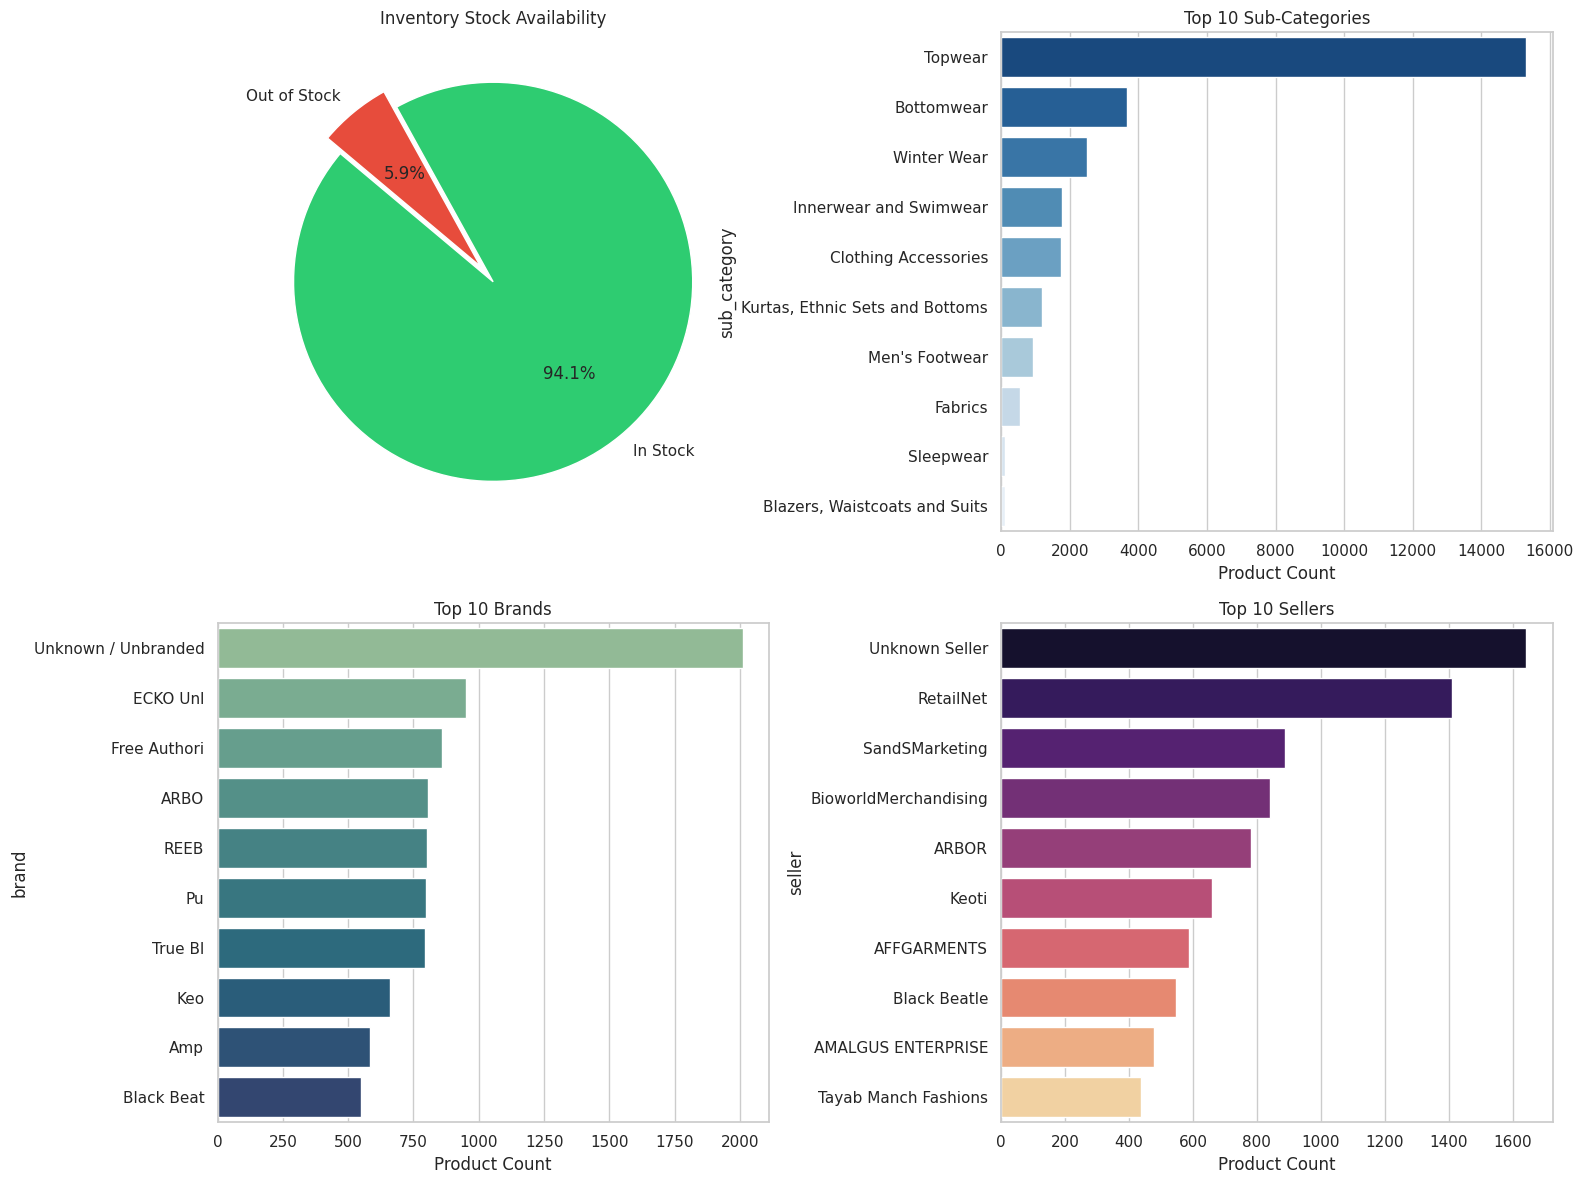

In [26]:
#Out of Stock Distribution
stock_counts = df_processed["out_of_stock"].value_counts()
stock_labels = ["In Stock", "Out of Stock"]

#Top Sellers & Top Brands
top_brands = df_processed["brand"].replace("", "Unknown / Unbranded").value_counts().head(10)
top_sellers = df_processed["seller"].replace("", "Unknown Seller").value_counts().head(10)
top_subcategories = df_processed["sub_category"].value_counts().head(10)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Pie Chart: Stock Availability
axes[0, 0].pie(stock_counts, labels=stock_labels, autopct="%1.1f%%", colors=["#2ecc71", "#e74c3c"], startangle=140, explode=(0, 0.1))
axes[0, 0].set_title("Inventory Stock Availability")

# Bar Chart: Top Categories/Subcategories
sns.barplot(x=top_subcategories.values, y=top_subcategories.index, ax=axes[0, 1], palette="Blues_r", hue=top_subcategories.index, legend=False)
axes[0, 1].set_title("Top 10 Sub-Categories")
axes[0, 1].set_xlabel("Product Count")

# Bar Chart: Top Brands
sns.barplot(x=top_brands.values, y=top_brands.index, ax=axes[1, 0], palette="crest", hue=top_brands.index, legend=False)
axes[1, 0].set_title("Top 10 Brands")
axes[1, 0].set_xlabel("Product Count")

# Bar Chart: Top Sellers
sns.barplot(x=top_sellers.values, y=top_sellers.index, ax=axes[1, 1], palette="magma", hue=top_sellers.index, legend=False)
axes[1, 1].set_title("Top 10 Sellers")
axes[1, 1].set_xlabel("Product Count")

plt.tight_layout()
plt.show()

Looking at these charts, almost all products (94.1%) are in stock, with only a small portion currently unavailable. Topwear is by far the most popular product category in the dataset, followed by Bottomwear and Winter Wear. Interestingly, a large number of products do not have a listed brand or seller, making "Unknown" the top category for both. Among the identified names, brands like ECKO Unl and sellers like RetailNet lead the catalog with the highest number of items.

# 3. Pricing, Discount, and Rating Rankings

Here we evaluate price distributions, discount percentages, ratings, and ranks products based on key numerical attributes.

NUMERICAL ATTRIBUTES SUMMARY


,selling_price_numeric,actual_price_numeric,discount_numeric,average_rating_numeric
count,28078.00,27303.00,27225.00,25819.00
mean,705.64,1455.53,50.26,3.63
std,549.68,939.98,16.89,0.66
min,99.00,150.00,1.00,1.00
25%,390.00,849.00,40.00,3.20
50%,545.00,1199.00,53.00,3.80
75%,820.00,1799.00,63.00,4.10
max,7999.00,12999.00,87.00,5.00



TOP 5 HIGHEST RATED PRODUCTS


,pid,title,brand,average_rating_numeric,selling_price_numeric
13251,VESFSJ92YXMAJZFX,Sheny Women Vest,,5.0,184.0
9482,TSHFJHFFQHQBNVSV,Solid Women Round Neck Red T-Shirt,FancyW,5.0,215.0
4683,TSHFVUXHTE5KH7RH,Solid Men Polo Neck Dark Blue T-Shirt,Shoef,5.0,246.0
417,BXRFGYUGJCWWZ7UG,Printed Men Boxer (Pack of 1),SayItLo,5.0,249.0
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,5.0,249.0



TOP 5 HIGHEST DISCOUNTED PRODUCTS (%)


,pid,title,brand,actual_price_numeric,selling_price_numeric,discount_numeric
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,998.0,128.0,87.0
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,999.0,136.0,86.0
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,999.0,136.0,86.0
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pa...,yellowvib,2999.0,449.0,85.0
9813,CAPE9YWMURE4FKAJ,Solid Balclava Cap,Gracew,1499.0,228.0,84.0



TOP 5 MOST EXPENSIVE PRODUCTS


,pid,title,brand,selling_price_numeric,actual_price_numeric
2067,TKTFZ3YGGMMNBYEZ,Solid Women Track Suit,REEB,7999.0,9999.0
11010,BZRFVAX2QGTEGHRH,Checkered Single Breasted Party Women Full Sle...,True Bl,7998.0,7999.0
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,7799.0,12999.0
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,7799.0,12999.0
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,7794.0,12990.0


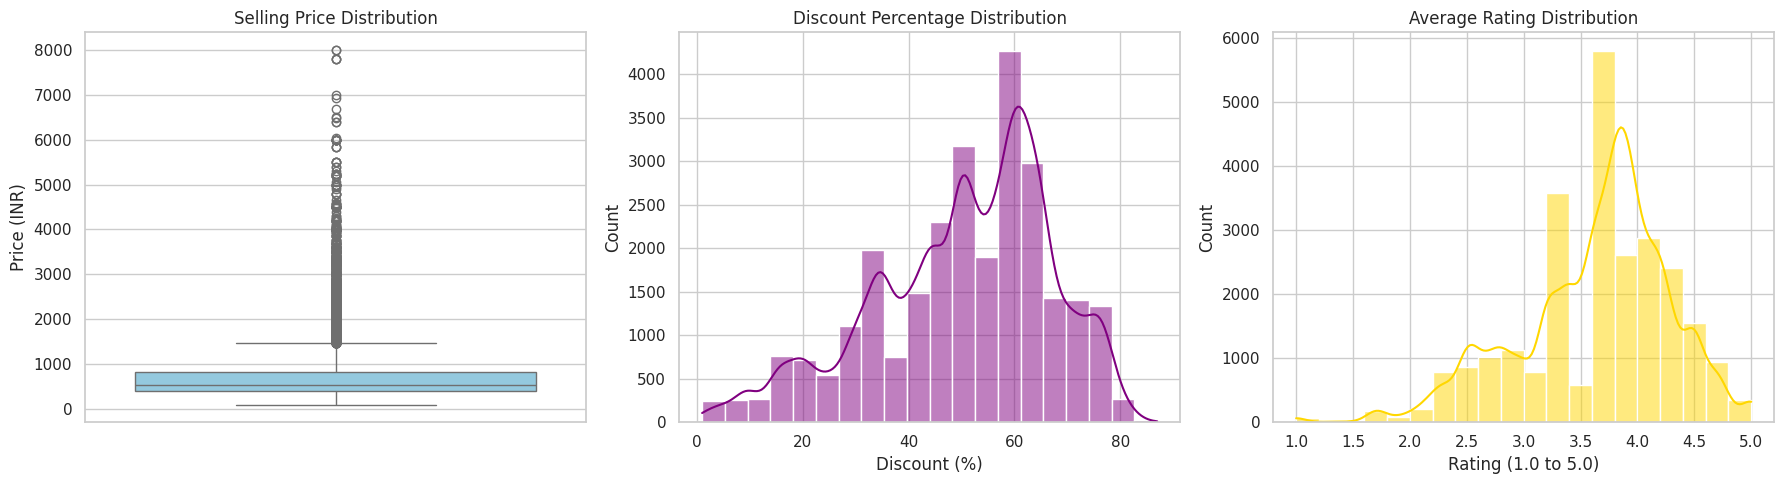

In [34]:
#Summary statistics for numerical variables
print( "NUMERICAL ATTRIBUTES SUMMARY")
display(df_processed[["selling_price_numeric", "actual_price_numeric", "discount_numeric", "average_rating_numeric"]].describe().round(2))

#Product Ranking
print("\nTOP 5 HIGHEST RATED PRODUCTS")
display(df_processed.sort_values(by=["average_rating_numeric", "selling_price_numeric"], ascending=[False, True])[["pid", "title", "brand", "average_rating_numeric", "selling_price_numeric"]].head(5))

print("\nTOP 5 HIGHEST DISCOUNTED PRODUCTS (%)")
display(df_processed.sort_values(by="discount_numeric", ascending=False)[["pid", "title", "brand", "actual_price_numeric", "selling_price_numeric", "discount_numeric"]].head(5))

print("\nTOP 5 MOST EXPENSIVE PRODUCTS")
display(df_processed.sort_values(by="selling_price_numeric", ascending=False)[["pid", "title", "brand", "selling_price_numeric", "actual_price_numeric"]].head(5))

#Visualization of Numeric Distributions
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(y=df_processed["selling_price_numeric"], ax=axes[0], color="skyblue")
axes[0].set_title("Selling Price Distribution")
axes[0].set_ylabel("Price (INR)")

sns.histplot(df_processed["discount_numeric"], bins=20, kde=True, ax=axes[1], color="purple")
axes[1].set_title("Discount Percentage Distribution")
axes[1].set_xlabel("Discount (%)")

sns.histplot(df_processed["average_rating_numeric"], bins=20, kde=True, ax=axes[2], color="gold")
axes[2].set_title("Average Rating Distribution")
axes[2].set_xlabel("Rating (1.0 to 5.0)")

plt.tight_layout()
plt.show()

Most products in the dataset are budget-friendly, with half selling for 545 INR or less, while a few expensive items like tracksuits and jackets reach up to 8,000 INR. Discounts are generous and common, averaging around 50% off and frequently peaking between 50% and 60%. Customer feedback is generally positive, with average ratings sitting around 3.6 out of 5 stars and strongly clustering near 3.8 stars. Overall, the dataset represents an affordable, highly discounted, and well-rated catalog, making these numeric attributes ideal for filtering and sorting search results rather than indexing them as text.

# 4. Word Clouds for High-Frequency Terms
We use Word clouds to visualize the dominant terms present in product titles and descriptions.

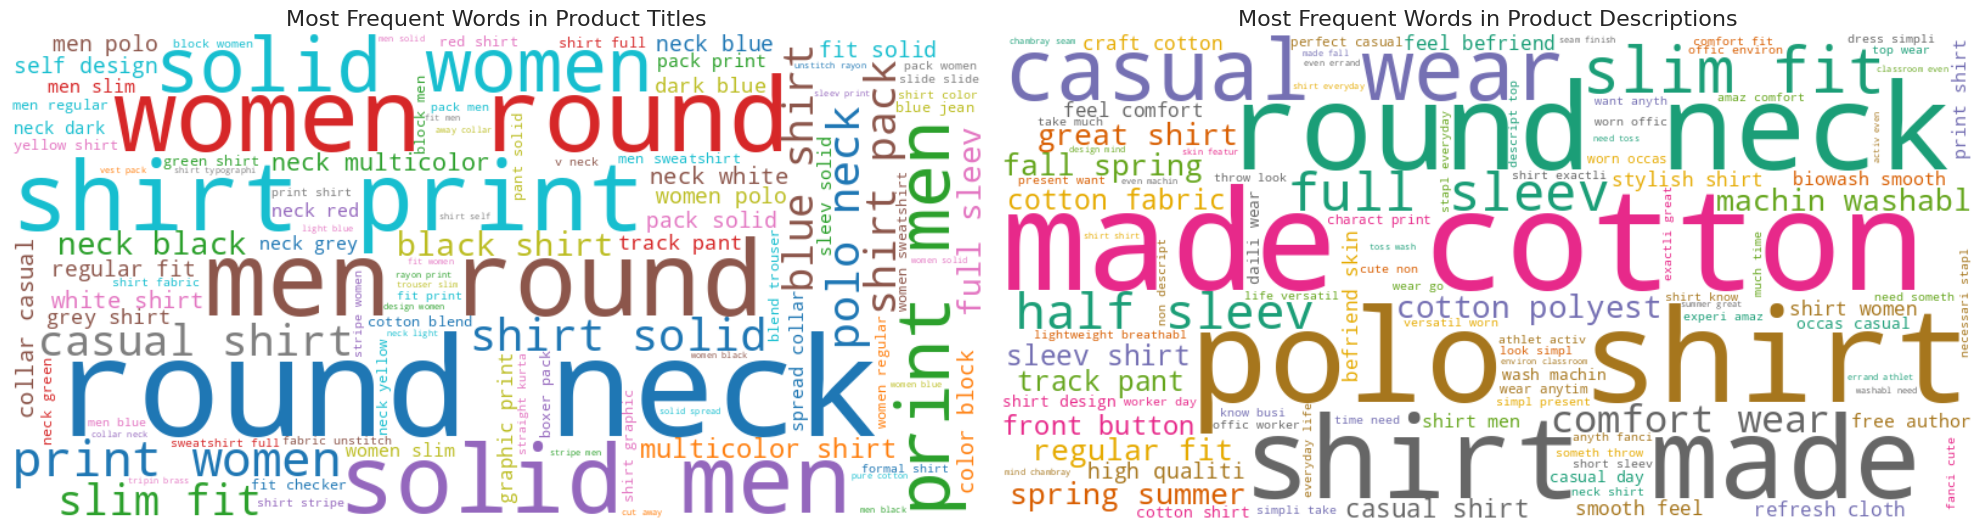

In [30]:
#Aggregate tokens for titles and descriptions
title_text_space = " ".join(all_title_tokens)
desc_text_space = " ".join(all_desc_tokens)

#Generate Word Clouds
wc_title = WordCloud(width=800, height=400, background_color="white", max_words=100, colormap="tab10").generate(title_text_space)
wc_desc = WordCloud(width=800, height=400, background_color="white", max_words=100, colormap="Dark2").generate(desc_text_space)

fig, axes = plt.subplots(1, 2, figsize=(20, 8))

axes[0].imshow(wc_title, interpolation="bilinear")
axes[0].set_title("Most Frequent Words in Product Titles", fontsize=16)
axes[0].axis("off")

axes[1].imshow(wc_desc, interpolation="bilinear")
axes[1].set_title("Most Frequent Words in Product Descriptions", fontsize=16)
axes[1].axis("off")

plt.tight_layout()
plt.show()

The word clouds show that product titles focus mainly on basic search terms like target audience (men, women), garment type (shirt, round neck), and appearance (solid, print). On the other hand, product descriptions highlight fabric materials (cotton), product feel (casual, comfort), and care details (made, machin washabl). Overall, titles contain essential terms to match user searches, while descriptions provide secondary details about product quality and materials.

# 5. Named Entity Recognition (NER)
Now we use  SpaCy to extract named entities (e.g., Brands, Organizations, Materials, and Products) from product titles to evaluate attribute patterns.

=== NAMED ENTITY RECOGNITION SUMMARY ===
Entity Label Counts:
Label
ORG            1382
PERSON          634
CARDINAL        558
GPE              38
WORK_OF_ART      22
FAC               4
PERCENT           3
DATE              3
QUANTITY          1
Name: count, dtype: int64

Top Entities per Category:
Label        Entity                                       
CARDINAL     2                                                220
             3                                                196
             4                                                 31
             6                                                 29
             1                                                 27
DATE         1307-9                                             1
             2010                                               1
             2021                                               1
FAC          Crew Black                                         2
             Kerala Traditional Mundu        

/tmp/ipykernel_2725/2672021725.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_entities, x="Label", order=df_entities["Label"].value_counts().index, palette="Set2")


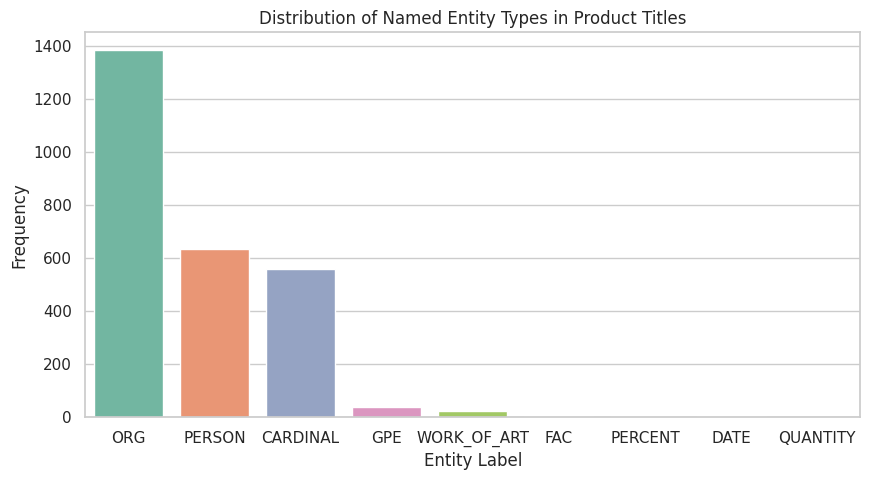

In [32]:
#Load spaCy English model
try:
    nlp = spacy.load("en_core_web_sm")
except:
    import subprocess
    subprocess.run(["python", "-m", "spacy", "download", "en_core_web_sm"])
    nlp = spacy.load("en_core_web_sm")

#Sample titles for efficient processing
sample_titles = df_processed["title"].dropna().sample(n=3000, random_state=42).tolist()

entities = []
for doc in nlp.pipe(sample_titles, batch_size=50):
    for ent in doc.ents:
        entities.append((ent.text, ent.label_))

#Convert to DataFrame
df_entities = pd.DataFrame(entities, columns=["Entity", "Label"])

print("NAMED ENTITY RECOGNITION SUMMARY")
print("Entity Label Counts:")
print(df_entities["Label"].value_counts())

# Top entities per label
top_ents = df_entities.groupby("Label")["Entity"].value_counts().groupby(level=0).head(5)
print("\nTop Entities per Category:")
print(top_ents)

# Plot top entity labels
plt.figure(figsize=(10, 5))
sns.countplot(data=df_entities, x="Label", order=df_entities["Label"].value_counts().index, palette="Set2")
plt.title("Distribution of Named Entity Types in Product Titles")
plt.xlabel("Entity Label")
plt.ylabel("Frequency")
plt.show()

The analysis shows that standard text-labeling models struggle to accurately categorize fashion product titles. While numbers (CARDINAL) were correctly picked up to identify pack quantities like "pack of 2" or "3", the model incorrectly labeled general fashion descriptors, such as "Solid Women" as a person (PERSON) and full product titles as organizations (ORG). Overall, the standard pre-trained models implemented here are not reliable for fashion datasets; for future improvements, building custom rules or category dictionaries would be a much better choice for extracting specific clothing attributes.

# Final conclusions
Our text analysis shows that product titles are short and direct, while descriptions are longer but frequently missing. Looking at prices, discounts, and ratings helps us understand how products are priced across top brands and sellers, as well as how many items are currently out of stock. Combining these text and price insights allows us to handle missing data, filter out unavailable items cleanly, and give more weight to titles so users can search, filter, and sort products accurately.